In [1]:
# nombre: Sofía Rojas
# rut : 22.532.158-2

In [11]:
import numpy as np
import matplotlib.pyplot as plt

In [33]:
rng = np.random.default_rng(seed=1410)

Parte 1

In [30]:
""" Arreglo temporal """
t = np.linspace(0, 10, 500) 
# Flujo normalizado de la estrella 
flujo = np.ones_like(t) #: 1 en todos los tiempo
# Flujo + ruido gaussiano
flujo = flujo + rng.normal(0, 0.002, 500)

""" Simulación de tránsitos """
t_i1, t_f1 = 4.5, 5.0
transito1 = (t>=t_i1) & (t<=t_f1)
flujo[transito1] -= 0.02

t_i2, t_f2 = 7.0, 7.4 
transito2 = (t>=t_i2) & (t<=t_f2)
flujo[transito2] -= 0.015

In [31]:
""" Función de curva de luz """

def fig_curva(t, flujo):
    """" Genera una figura de la curva de luz de una estrella con tránsitos planetarios.

    Parameters
    ----------
    t : array_like
        Arreglo de tiempos.
    flujo : array_like
        Arreglo de flujos.

    Returns
    -------
    plt.Figure
        Figura de la curva de luz.
    """
    # Cálculo para valores de umbral de detección 

    f_mean = np.mean(flujo)
    std = np.std(flujo)
    condicion = f_mean - 3 * std 
    puntos_umbral = flujo < condicion 

    # Creación de la figura
    plt.figure(figsize=(12, 6))
    
    plt.plot(t, flujo, marker = "*", color='pink', label='Curva de luz')
    
    # Resaltando los puntos por debajo del umbral de detección
    plt.scatter(t[puntos_umbral], flujo[puntos_umbral], color='crimson', label='Puntos por debajo del umbral')

    # Etiquetas para ambos ejes (Con fontsize 14) y tíyulo de la figura 

    plt.xlabel('Tiempo (años)', fontsize=14)
    plt.ylabel('Flujo normalizado', fontsize=14)
    plt.legend(fontsize= 14)
    plt.title('Curva de la luz', fontsize=15, color='pink')

    # Lineas Horizontales/Verticales

    plt.axhline(f_mean, color= 'crimson', linestyle='--', label='Media del flujo')
    plt.axhline(condicion, color='crimson', linestyle='--', label='Umbral de detección')

    plt.axvline(t_i1, color='crimson', linestyle='--', label='Inicio del tránsito 1')
    plt.axvline(t_f1, color='crimson', linestyle='--', label='Fin del tránsito 1')

    plt.axvline(t_i2, color='crimson', linestyle='--', label='Inicio del tránsito 2')
    plt.axvline(t_f2, color='crimson', linestyle='--', label='Fin del tránsito 2')

    plt.show()

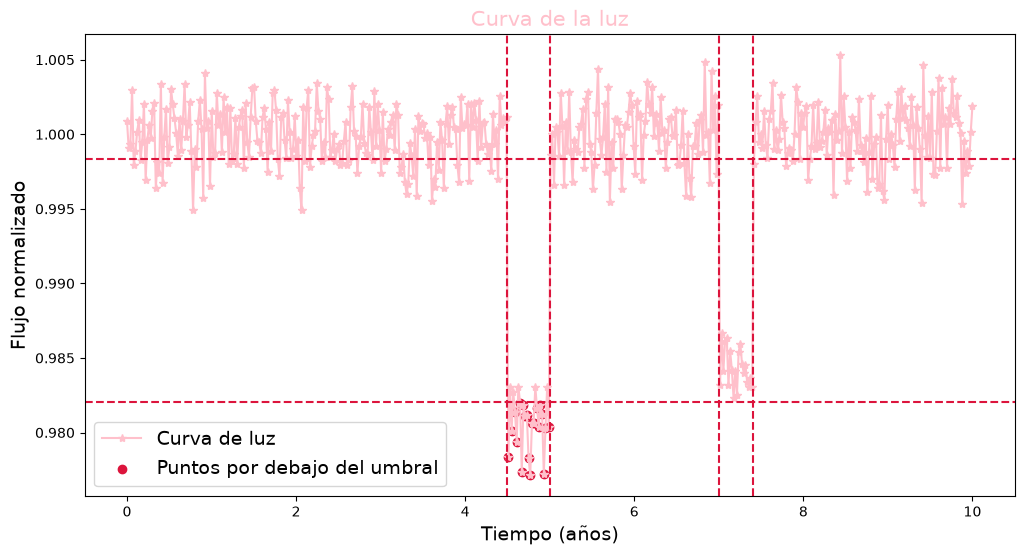

In [32]:
# Simulación de la curva de luz

fig_curva(t, flujo)

Parte 2

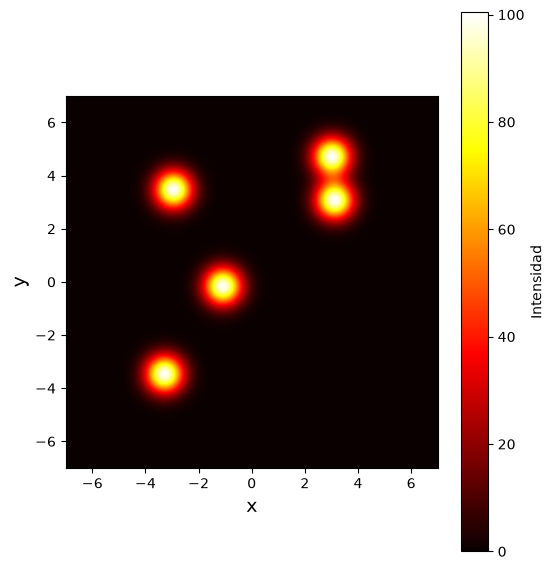

In [45]:
""" a) Terminos iniciales """

N_estrellas = 5 # Para el ejemplo, generaremos una imagen con 5 estrellas

i0 = 100
sigma = 0.5
x0 = rng.uniform(-5, 5, N_estrellas)
y0 = rng.uniform(-5, 5, N_estrellas)

x = np.linspace(-7, 7, 500)
y = np.linspace(-7, 7, 500)
X, Y = np.meshgrid(x, y)

# Cálculo de la intensidad
I_total = np.zeros_like(X)
for xi, yi in zip(x0, y0):
  I_total += i0 * np.exp(-((X - xi) ** 2 + (Y - yi) ** 2) / (2 * sigma**2))

# Gráfico 
plt.figure(figsize=(6, 7))
plt.imshow(I_total, origin="lower", extent=(-7, 7, -7, 7), cmap="hot")
plt.colorbar(label="Intensidad")
plt.xlabel("x", fontsize=14)
plt.ylabel("y", fontsize=14)
plt.show()

In [ ]:
""" b) Función para calcular las distancias euclidianas """

def calcular_distancias(x0, y0):
  coords = np.column_stack((x0, y0))
  diff = coords[:, np.newaxis, :] - coords[np.newaxis, :, :]
  distancias = np.linalg.norm(diff, axis=-1)
  return distancias
